In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
sns.set_theme(style="whitegrid")

train = pd.read_csv("train-test.csv")
validation = pd.read_csv("validation.csv")


In [10]:
print("Training shape:", train.shape)
print("Validation shape:", validation.shape)


Training shape: (48000, 14)
Validation shape: (12000, 13)


In [14]:
print("\nTraining columns:")
print(train.columns.tolist())



Training columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']


In [15]:
print("\nValidation columns:")
print(validation.columns.tolist())


Validation columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']


In [12]:
display(train.head())

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [13]:
display(validation.head())

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [20]:
# Data types and missing values
print("TRAINING DATA")
train.info()

TRAINING DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [21]:
print("\nVALIDATION DATA")
validation.info()



VALIDATION DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       12000 non-null  object 
 1   pickup        12000 non-null  object 
 2   delivery      12000 non-null  object 
 3   pickup_lat    12000 non-null  float64
 4   pickup_lon    12000 non-null  float64
 5   delivery_lat  12000 non-null  float64
 6   delivery_lon  12000 non-null  float64
 7   distance      12000 non-null  float64
 8   equipment     12000 non-null  object 
 9   weight        11835 non-null  float64
 10  date          12000 non-null  object 
 11  market_index  11751 non-null  float64
 12  quote_signal  12000 non-null  float64
dtypes: float64(8), object(5)
memory usage: 1.2+ MB


In [22]:

# Missing-value report
missing_report = pd.DataFrame({
    "Train Missing": train.isnull().sum(),
    "Train Missing %": train.isnull().mean() * 100,
    "Validation Missing": validation.isnull().sum(),
    "Validation Missing %": validation.isnull().mean() * 100
}).fillna(0)

display(missing_report.round(2))


,Train Missing,Train Missing %,Validation Missing,Validation Missing %
date,0,0.00,0.0,0.00
delivery,0,0.00,0.0,0.00
delivery_lat,0,0.00,0.0,0.00
delivery_lon,0,0.00,0.0,0.00
distance,0,0.00,0.0,0.00
equipment,0,0.00,0.0,0.00
load_id,0,0.00,0.0,0.00
market_index,374,0.78,249.0,2.08
pickup,0,0.00,0.0,0.00
pickup_lat,0,0.00,0.0,0.00


In [23]:
print("Duplicate training rows:", train.duplicated().sum())
print("Duplicate validation rows:", validation.duplicated().sum())


Duplicate training rows: 0
Duplicate validation rows: 0


In [24]:

print("Unique training load IDs:", train["load_id"].nunique())
print("Unique validation load IDs:", validation["load_id"].nunique())

Unique training load IDs: 48000
Unique validation load IDs: 12000


In [25]:

print("Columns only in training:")
print(sorted(set(train.columns) - set(validation.columns)))

print("\nColumns only in validation:")
print(sorted(set(validation.columns) - set(train.columns)))

print("\nTraining date range:")
print(pd.to_datetime(train["date"], errors="coerce").agg(["min", "max"]))

print("\nValidation date range:")
print(pd.to_datetime(validation["date"], errors="coerce").agg(["min", "max"]))


Columns only in training:
['posted_rate']

Columns only in validation:
[]

Training date range:
min   2025-01-01
max   2025-10-31
Name: date, dtype: datetime64[ns]

Validation date range:
min   2025-11-01
max   2025-12-31
Name: date, dtype: datetime64[ns]


In [30]:

numeric_cols = [
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon",
    "distance", "weight", "market_index", "quote_signal"
]

,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.648,4.315,28.358,31.987,35.295,39.411,44.303
pickup_lon,48000.0,-90.929,13.482,-121.698,-98.401,-88.089,-83.285,-69.500
delivery_lat,48000.0,35.641,4.317,28.358,31.987,35.295,39.411,44.303
delivery_lon,48000.0,-90.857,13.477,-121.698,-98.401,-87.529,-83.285,-69.500
distance,48000.0,1135.857,728.564,70.000,550.400,953.300,1645.525,3439.800
weight,47700.0,31028.844,9391.441,-47500.000,25800.000,31436.500,37018.000,47500.000
market_index,47626.0,1.083,0.168,0.676,0.950,1.056,1.220,1.468
quote_signal,48000.0,2.062,0.291,0.692,1.891,2.056,2.222,3.610


array([[<Axes: title={'center': 'pickup_lat'}>,
        <Axes: title={'center': 'pickup_lon'}>,
        <Axes: title={'center': 'delivery_lat'}>],
       [<Axes: title={'center': 'delivery_lon'}>,
        <Axes: title={'center': 'distance'}>,
        <Axes: title={'center': 'weight'}>],
       [<Axes: title={'center': 'market_index'}>,
        <Axes: title={'center': 'quote_signal'}>, <Axes: >]], dtype=object)

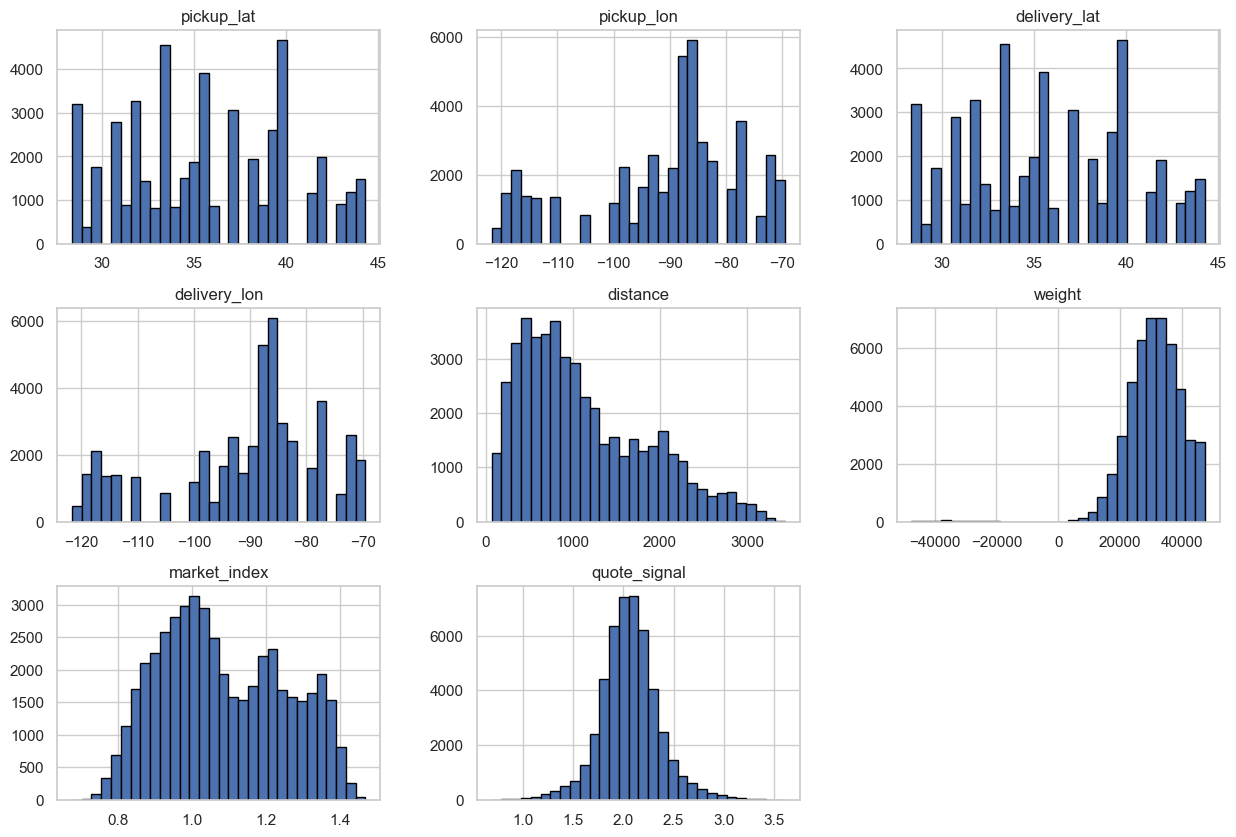

In [31]:
numeric_cols = [c for c in numeric_cols if c in train.columns]

display(train[numeric_cols].describe().T.round(3))

train[numeric_cols].hist(
    bins=30, figsize=(15, 10), edgecolor="black"
)

In [29]:
plt.suptitle("Training Data: Numerical Feature Distributions")
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64


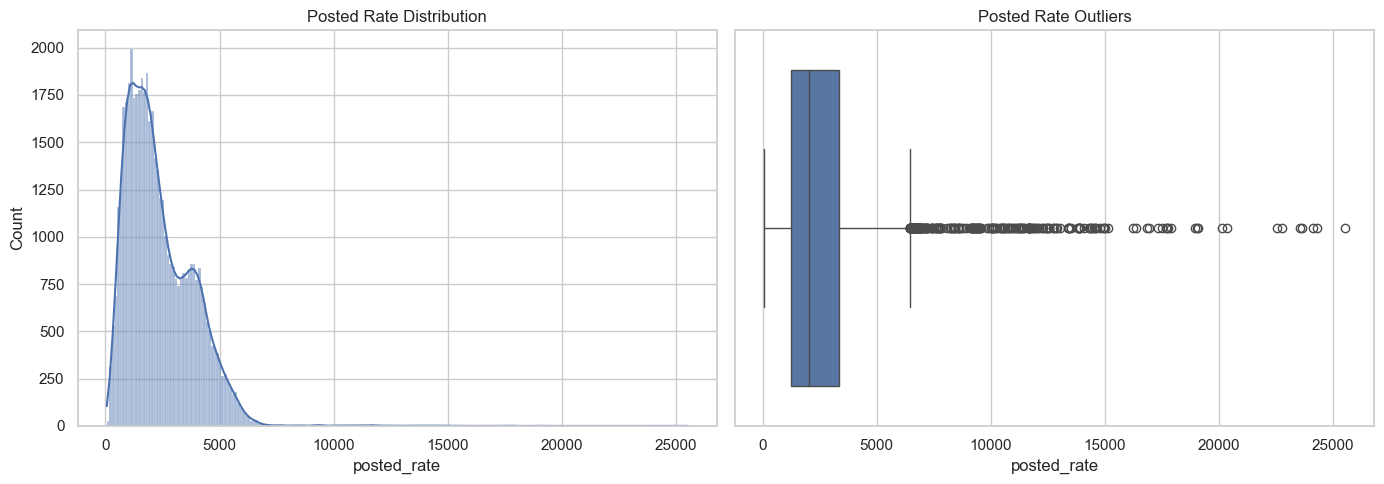

In [27]:

if "posted_rate" in train.columns:
    print(train["posted_rate"].describe())

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.histplot(
        train["posted_rate"].dropna(),
        kde=True, ax=axes[0]
    )
    axes[0].set_title("Posted Rate Distribution")

    sns.boxplot(
        x=train["posted_rate"], ax=axes[1]
    )
    axes[1].set_title("Posted Rate Outliers")

    plt.tight_layout()
    plt.show()



Top 10 values for pickup


,Count
pickup,
Oklahoma City,1242
Lexington,1209
Bakersfield,1193
Fort Wayne,1170
Hartford,1150
Richmond,1140
Nashville,1124
Phoenix,1121
Baton Rouge,1115



Top 10 values for delivery


,Count
delivery,
Lexington,1197
Fort Wayne,1176
Baton Rouge,1167
Bakersfield,1156
Hartford,1143
Oklahoma City,1140
Richmond,1109
Atlanta,1096
Phoenix,1090



Top 10 values for equipment


,Count
equipment,
Dry Van,27202
Reefer,12045
Flatbed,8753


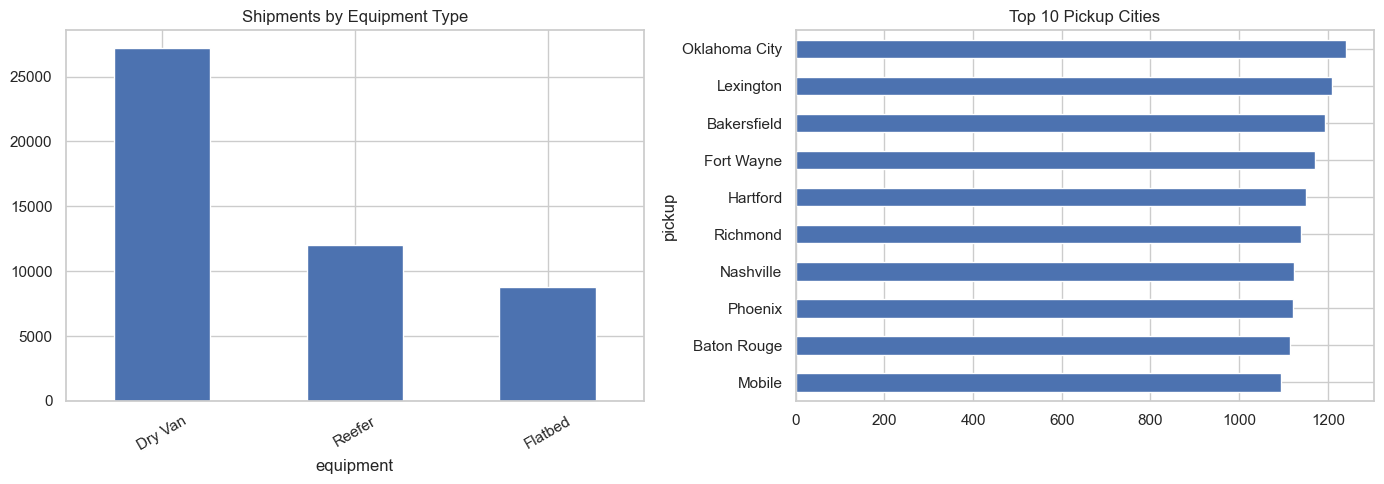

In [32]:

for col in ["pickup", "delivery", "equipment"]:
    if col in train.columns:
        print(f"\nTop 10 values for {col}")
        display(train[col].value_counts().head(10).to_frame("Count"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train["equipment"].value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Shipments by Equipment Type")
axes[0].tick_params(axis="x", rotation=30)

train["pickup"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top 10 Pickup Cities")

plt.tight_layout()
plt.show()


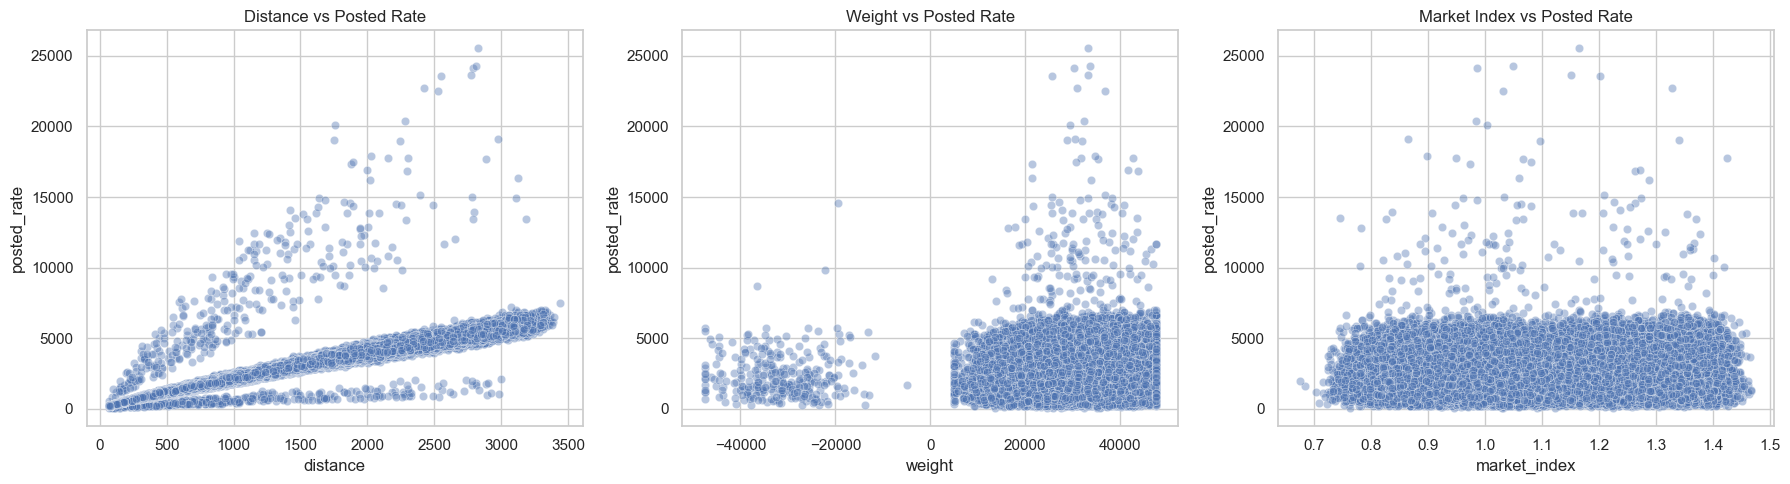

,count,mean,median
equipment,,,
Reefer,12045,2553.64,2196.67
Flatbed,8753,2445.09,2076.81
Dry Van,27202,2271.55,1953.04


In [33]:
## Categorical analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=train, x="distance", y="posted_rate",
    alpha=0.4, ax=axes[0]
)
axes[0].set_title("Distance vs Posted Rate")

sns.scatterplot(
    data=train, x="weight", y="posted_rate",
    alpha=0.4, ax=axes[1]
)
axes[1].set_title("Weight vs Posted Rate")

sns.scatterplot(
    data=train, x="market_index", y="posted_rate",
    alpha=0.4, ax=axes[2]
)
axes[2].set_title("Market Index vs Posted Rate")

plt.tight_layout()
plt.show()

# Average freight rate by equipment
display(
    train.groupby("equipment")["posted_rate"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .round(2)
)


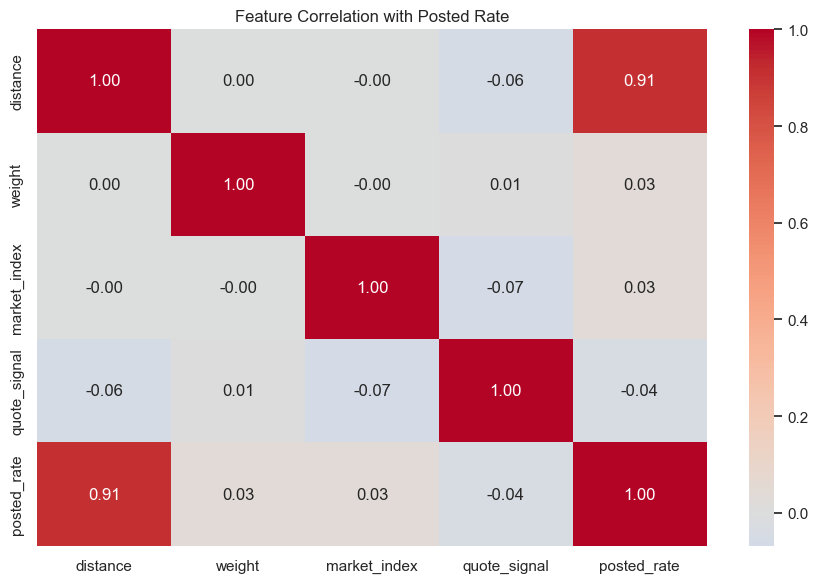

Correlation with posted_rate:


,Correlation
distance,0.908519
quote_signal,-0.039858
weight,0.034840
market_index,0.034165


In [35]:
# Correlation analysis
corr_cols = [
    "distance", "weight", "market_index",
    "quote_signal", "posted_rate"
]

corr_cols = [c for c in corr_cols if c in train.columns]

corr = train[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr, annot=True, fmt=".2f",
    cmap="coolwarm", center=0
)
plt.title("Feature Correlation with Posted Rate")
plt.tight_layout()
plt.show()

print("Correlation with posted_rate:")
display(
    corr["posted_rate"]
    .drop("posted_rate")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation")
)


## Prepare features for machine learning
#### We will predict posted_rate using the `training dataset`. The validation dataset will be kept separate until the model is selected.

In [37]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Preserve original data
tr = train.copy()
val = validation.copy()

# Clean target
tr["posted_rate"] = pd.to_numeric(
    tr["posted_rate"], errors="coerce"
)
tr = tr.dropna(subset=["posted_rate"]).copy()

# Create calendar features consistently
for frame in [tr, val]:
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame["year"] = frame["date"].dt.year
    frame["month"] = frame["date"].dt.month
    frame["day"] = frame["date"].dt.day
    frame["day_of_week"] = frame["date"].dt.dayofweek
    frame.drop(columns=["date", "load_id"], errors="ignore", inplace=True)

# Use only features present in both datasets
feature_cols = [
    c for c in tr.columns
    if c != "posted_rate" and c in val.columns
]

X = tr[feature_cols].copy()
y = tr["posted_rate"].copy()
X_validation = val[feature_cols].copy()

In [38]:
X_validation

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,quote_signal,year,month,day,day_of_week
0,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,0.90402,1.86388,2025,11,1,5
1,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,0.92851,1.86240,2025,11,1,5
2,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,0.88117,1.95480,2025,11,1,5
3,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,0.89156,2.14579,2025,11,1,5
4,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,0.88308,2.22541,2025,11,1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,377.4,Dry Van,38638.0,1.03391,2.15984,2025,12,31,2
11996,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,707.4,Dry Van,27685.0,0.99846,2.46279,2025,12,31,2
11997,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,359.4,Flatbed,35522.0,0.98564,2.09568,2025,12,31,2
11998,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,1750.8,Dry Van,31755.0,1.03100,1.95125,2025,12,31,2


In [39]:
# Ensure numerical features are numeric
for col in feature_cols:
    if col in [
        "pickup_lat", "pickup_lon", "delivery_lat",
        "delivery_lon", "distance", "weight",
        "market_index", "quote_signal",
        "year", "month", "day", "day_of_week"
    ]:
        X[col] = pd.to_numeric(X[col], errors="coerce")
        X_validation[col] = pd.to_numeric(
            X_validation[col], errors="coerce"
        )

categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

In [40]:
print("Features used:", feature_cols)
print("Training features shape:", X.shape)
print("Validation features shape:", X_validation.shape)

Features used: ['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'market_index', 'quote_signal', 'year', 'month', 'day', 'day_of_week']
Training features shape: (48000, 15)
Validation features shape: (12000, 15)


In [42]:
## Split the training data
# Use chronological split when meaningful date variation exists
split_dates = pd.to_datetime(
    train.loc[tr.index, "date"], errors="coerce"
)

if split_dates.notna().all() and split_dates.nunique() > 1:
    ordered_idx = split_dates.sort_values(
        kind="stable"
    ).index

    cut = int(len(ordered_idx) * 0.80)

    train_idx = ordered_idx[:cut]
    test_idx = ordered_idx[cut:]

    X_train, X_test = X.loc[train_idx], X.loc[test_idx]
    y_train, y_test = y.loc[train_idx], y.loc[test_idx]
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

In [43]:
print("Training rows:", len(X_train))

Training rows: 38400


In [44]:
print("Testing rows:", len(X_test))

Testing rows: 9600


In [46]:
## Build preprocessing and ML pipelines
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=20,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": Pipeline([
        ("encode", preprocessor),
        ("to_dense", __import__("sklearn").preprocessing.FunctionTransformer(
            lambda x: x.toarray() if hasattr(x, "toarray") else x
        )),
        ("model", HistGradientBoostingRegressor(
            max_iter=100, random_state=42
        ))
    ])
}


In [50]:

import os
os.environ["LOKY_MAX_CPU_COUNT"] = "2"

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import FunctionTransformer

# Update ensemble models to use limited CPU parallelism
models["Random Forest"] = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=2,
    random_state=42, n_jobs=2
)

models["Extra Trees"] = ExtraTreesRegressor(
    n_estimators=100, min_samples_leaf=2,
    random_state=42, n_jobs=2
)

# Prepare all six algorithms
models["Hist Gradient Boosting"] = Pipeline([
    ("preprocessor", preprocessor),
    ("to_dense", FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, "toarray") else x
    )),
    ("model", HistGradientBoostingRegressor(
        max_iter=100, random_state=42
    ))
])

results = []
trained_models = {}

for name, model in models.items():
    if name == "Hist Gradient Boosting":
        pipeline = model
    else:
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Algorithm": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

    trained_models[name] = pipeline
    print(f"Finished: {name}")

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nModel Comparison (best RMSE first)")
display(results_df.round(3))

best_name = results_df.iloc[0]["Algorithm"]
print("Best algorithm:", best_name)
print("Best RMSE:", round(results_df.iloc[0]["RMSE"], 3))


Training Linear Regression...
Finished: Linear Regression
Training Decision Tree...
Finished: Decision Tree
Training Random Forest...
Finished: Random Forest
Training Extra Trees...
Finished: Extra Trees
Training Gradient Boosting...
Finished: Gradient Boosting
Training Hist Gradient Boosting...
Finished: Hist Gradient Boosting

Model Comparison (best RMSE first)


,Algorithm,MAE,RMSE,R2
0,Hist Gradient Boosting,130.650,635.358,0.826
1,Gradient Boosting,130.238,636.455,0.826
2,Linear Regression,146.694,637.467,0.825
3,Random Forest,144.005,648.672,0.819
4,Extra Trees,153.025,669.623,0.807
5,Decision Tree,166.835,678.932,0.802


Best algorithm: Hist Gradient Boosting
Best RMSE: 635.358


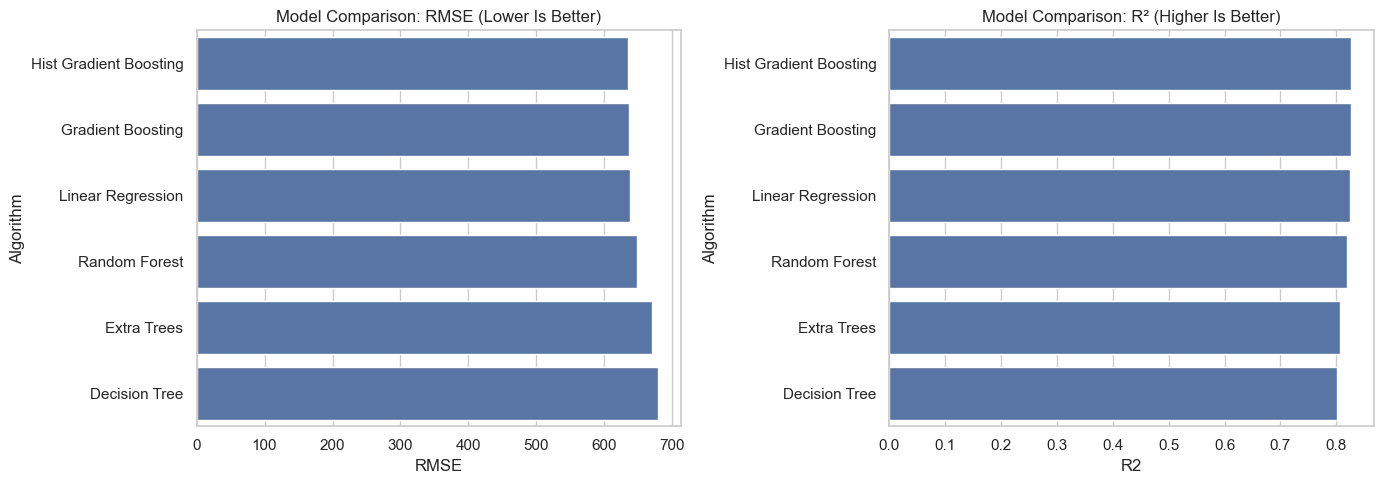

Best model based on holdout RMSE: Hist Gradient Boosting


In [51]:
## Plot the model comparison


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=results_df, x="RMSE", y="Algorithm", ax=axes[0]
)
axes[0].set_title("Model Comparison: RMSE (Lower Is Better)")

sns.barplot(
    data=results_df, x="R2", y="Algorithm", ax=axes[1]
)
axes[1].set_title("Model Comparison: R² (Higher Is Better)")

plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["Algorithm"]
print("Best model based on holdout RMSE:", best_name)


# Predict freight rates for `validation.csv`
### After comparing the models, refit the selected algorithm on all labeled training data and generate predictions for the separate validation dataset.

In [52]:

best_model = trained_models[best_name]

# Train selected model on all labeled training data
best_model.fit(X, y)

# Predict rates for the validation records
validation_predictions = best_model.predict(X_validation)

# Create output with original shipment IDs
prediction_output = pd.DataFrame({
    "load_id": validation["load_id"],
    "predicted_posted_rate": validation_predictions
})

display(prediction_output.head(10))

prediction_output.to_csv(
    "validation_predictions.csv", index=False
)

print("aved predictions to validation_predictions.csv")


,load_id,predicted_posted_rate
0,TE-000001,869.399473
1,TE-000002,5004.652661
2,TE-000003,5419.260088
3,TE-000004,4141.008054
4,TE-000005,1828.486785
5,TE-000006,4567.732376
6,TE-000007,5167.160671
7,TE-000008,2963.611046
8,TE-000009,1111.607433
9,TE-000010,1180.318518


Saved predictions to validation_predictions.csv


In [ ]:
data = pd.read_csv("S")